# Entrenamiento de un modelo propio (YOLO26) y comparación con el modelo de Roboflow
**UBO · Desarrollo de Soluciones Inteligentes · Proyecto Integrador 2026 S2** · Detector de casco de seguridad

Este notebook:
1. Entrena **YOLO26** (Ultralytics) con el dataset *Hard Hats v6* (el mismo zip de la bitácora de validación).
2. Evalúa el modelo en la partición **test**, que **no se usó para entrenar**.
3. Lo compara con el modelo alojado en Roboflow sobre **las mismas imágenes de test**, con las mismas métricas de la bitácora (alternativas comparadas con evidencia).
4. Deja un archivo `.pt` que la app Gradio puede usar **sin API key, sin créditos y más rápido**.

**Antes de empezar:** en Colab usa *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Sin GPU el entrenamiento es inviable. El zip debe estar en tu Drive. Todo lo que se entrena se guarda en tu Drive, así que si Colab se desconecta puedes **reanudar** (celda de entrenamiento).

In [ ]:
# Colab ya trae torch, opencv, pillow y pandas. Solo se instala ultralytics si falta.
import importlib.util
if importlib.util.find_spec("ultralytics") is None:
    get_ipython().run_line_magic("pip", "install -q ultralytics")
    print("ultralytics instalado. Si luego sale un ImportError, usa Entorno de ejecución > Reiniciar sesión y ejecuta desde la celda de configuración.")
else:
    print("ultralytics ya disponible.")

ultralytics instalado. Si luego sale un ImportError, usa Entorno de ejecución > Reiniciar sesión y ejecuta desde la celda de configuración.


In [ ]:
# ===== CONFIGURACIÓN =====
EQUIPO = "COMPLETAR: nombre del equipo"
DATASET_ZIP = "/content/drive/MyDrive/AMIR/DATASET_ZIP/Hard Hats.v6-resized640_noaugmentation-rf-detr.yolo26.zip"   # el mismo zip de la bitácora (formato YOLO)
SALIDA = "/content/drive/MyDrive/entrenamiento_casco"             # TODO se guarda aquí (Drive): sobrevive a desconexiones
NOMBRE_CORRIDA = "yolo26n_hardhat"

MODELO_BASE = "yolo26n.pt"   # pesos preentrenados de Ultralytics (n = el más pequeño y rápido; también existen s, m, l, x)
EPOCAS = 30                  # pasadas completas por el dataset
IMGSZ = 640                  # tamaño de imagen (el dataset ya viene a 640x640)
BATCH = 16                   # baja a 8 si sale error de memoria
PACIENCIA = 10               # se detiene antes si no mejora en 10 épocas
SEED = 42

# Para comparar con la bitácora: MISMA muestra de imágenes (misma semilla y mismo N) y mismo IoU
N_AJUSTE = 150
N_FINAL = 200
IOU_MIN = 0.5
CONF_MIN = 0.10
UMBRAL_ROBOFLOW = 0.50       # el umbral que eligieron en la bitácora para el modelo de Roboflow
PRED_ROBOFLOW_TEST = "/content/drive/MyDrive/pred_test.json"   # lo genera Bitacora_Validacion.ipynb: cópialo a Drive para comparar
USAR_DRIVE = True

In [ ]:
import os, re, io, json, zipfile, random, time, shutil, warnings
from datetime import datetime
from collections import Counter
import numpy as np, pandas as pd
from PIL import Image, ImageDraw, ImageOps
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings("ignore")

if USAR_DRIVE and not os.path.exists(DATASET_ZIP):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("No se pudo montar Drive:", e)
assert os.path.exists(DATASET_ZIP), f"No encuentro el zip en {DATASET_ZIP}."
os.makedirs(SALIDA, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == 0 else "NO HAY GPU -> activa una GPU en Entorno de ejecución, o el entrenamiento será extremadamente lento")

GPU: Tesla T4


## 1 · Datos
Se descomprime el zip y se crea un `data.yaml` con rutas absolutas (el original usa rutas relativas que no sirven en Colab). Además se carga la **misma muestra reproducible** de la bitácora para comparar modelos en igualdad de condiciones.

In [ ]:
CATS = ["casco", "sin_casco"]
NOMBRE = {"casco": "Casco", "sin_casco": "Sin casco"}

def categoria(nombre):
    n = " ".join(re.sub(r"[^a-z0-9]+", " ", str(nombre).lower()).split())
    if re.search(r"\b(no|sin|without)\b.*(helmet|hardhat|hard hat|casco)|nohelmet|nohardhat", n):
        return "sin_casco"
    if re.search(r"helmet|hardhat|hard hat|casco", n):
        return "casco"
    return "otra"

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0.0

ZIP = zipfile.ZipFile(DATASET_ZIP)
NOMBRES_ZIP = ZIP.namelist()
import yaml
_yml = [n for n in NOMBRES_ZIP if n.endswith("data.yaml")][0]
_names = yaml.safe_load(ZIP.read(_yml))["names"]
CLASES_DATASET = [_names[k] for k in sorted(_names)] if isinstance(_names, dict) else list(_names)
MAPA_CLASES = {i: categoria(n) for i, n in enumerate(CLASES_DATASET)}

def listar_split(split):
    pats = {"valid": ["valid", "val"], "test": ["test"]}[split]
    for p in pats:
        imgs = sorted(n for n in NOMBRES_ZIP if re.search(rf"(^|/){p}/images/[^/]+\.(jpg|jpeg|png)$", n, re.I))
        if imgs:
            return imgs
    return []

def cargar_gt(zname, W, H):
    base, _, resto = zname.rpartition("/images/")
    lab = f"{base}/labels/{resto.rsplit('.', 1)[0]}.txt" if base else f"labels/{resto.rsplit('.', 1)[0]}.txt"
    if lab not in NOMBRES_ZIP:
        return []
    out = []
    for linea in ZIP.read(lab).decode().splitlines():
        p = linea.split()
        if len(p) < 5: continue
        c = int(float(p[0])); v = list(map(float, p[1:]))
        if len(v) == 4:
            cx, cy, w, h = v; x1, y1, x2, y2 = (cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H
        else:                                   # polígono: se toma su caja envolvente
            xs, ys = v[0::2], v[1::2]; x1, y1, x2, y2 = min(xs)*W, min(ys)*H, max(xs)*W, max(ys)*H
        cat = MAPA_CLASES.get(c, "otra")
        if cat in CATS:
            out.append({"cat": cat, "box": (x1, y1, x2, y2), "area": ((x2-x1)*(y2-y1))/(W*H)})
    return out

def tomar_muestra(split, n, carpeta):
    todos = listar_split(split)
    assert todos, f"No encontré imágenes de la partición '{split}' en el zip."
    elegidos = sorted(random.Random(SEED).sample(todos, min(n, len(todos))))
    os.makedirs(carpeta, exist_ok=True); muestra = []
    for z in elegidos:
        ruta = os.path.join(carpeta, os.path.basename(z))
        with open(ruta, "wb") as f: f.write(ZIP.read(z))
        W, H = Image.open(ruta).size
        muestra.append({"id": os.path.basename(z), "path": ruta, "W": W, "H": H, "gt": cargar_gt(z, W, H)})
    return muestra, len(todos)

MUESTRA_AJ, TOTAL_AJ = tomar_muestra("valid", N_AJUSTE, "/content/val_valid")
MUESTRA_FIN, TOTAL_FIN = tomar_muestra("test", N_FINAL, "/content/val_test")

def resumen_muestra(m):
    c = Counter(b["cat"] for im in m for b in im["gt"])
    return len(m), c["casco"], c["sin_casco"], sum(1 for im in m if any(b["cat"] == "sin_casco" for b in im["gt"]))

tabla_datos = pd.DataFrame(
    [["valid (ajuste de umbral)", TOTAL_AJ, *resumen_muestra(MUESTRA_AJ)],
     ["test (evaluación final)", TOTAL_FIN, *resumen_muestra(MUESTRA_FIN)]],
    columns=["partición", "imágenes en el dataset", "imágenes en la muestra", "cajas 'casco'", "cajas 'sin casco'", "imágenes con 'sin casco'"])
print("Clases del dataset y su categoría:", {n: MAPA_CLASES[i] for i, n in enumerate(CLASES_DATASET)})
tabla_datos

Clases del dataset y su categoría: {'Hardhat': 'casco', 'NO-Hardhat': 'sin_casco'}


,partición,imágenes en el dataset,imágenes en la muestra,cajas 'casco',cajas 'sin casco',imágenes con 'sin casco'
0,valid (ajuste de umbral),3962,150,315,97,34
1,test (evaluación final),2001,200,402,128,40


In [ ]:
# Descomprime todo el dataset (puede tardar unos minutos) y crea el data.yaml para Ultralytics
RAIZ = "/content/dataset"
if not os.path.exists(os.path.join(RAIZ, ".listo")):
    shutil.rmtree(RAIZ, ignore_errors=True); ZIP.extractall(RAIZ); open(os.path.join(RAIZ, ".listo"), "w").write("ok")
_y = [os.path.join(d, f) for d, _, fs in os.walk(RAIZ) for f in fs if f == "data.yaml"][0]
RAIZ_DATOS = os.path.dirname(_y)
split_valid = "valid" if os.path.isdir(os.path.join(RAIZ_DATOS, "valid", "images")) else "val"
DATA_YAML = os.path.join(SALIDA, "dataset_casco.yaml")
import yaml
yaml.safe_dump({"path": RAIZ_DATOS, "train": "train/images", "val": f"{split_valid}/images", "test": "test/images",
                "names": {i: n for i, n in enumerate(CLASES_DATASET)}}, open(DATA_YAML, "w"))
for s in ["train", split_valid, "test"]:
    n = len([f for f in os.listdir(os.path.join(RAIZ_DATOS, s, "images"))])
    print(f"{s}: {n} imágenes")
print("Clases:", CLASES_DATASET)

train: 13782 imágenes
valid: 3962 imágenes
test: 2001 imágenes
Clases: ['Hardhat', 'NO-Hardhat']


## 2 · Entrenamiento
Se parte de pesos **preentrenados** (*transfer learning*) y se ajustan a las dos clases. Los puntos de control se guardan en tu Drive en cada época. **Si Colab se corta**, pon `RESUMIR = True` y vuelve a ejecutar solo esta celda (y las de configuración e imports antes).

Tiempo orientativo: de 1 a 3 horas en una T4 con 30 épocas. No lo he medido con este dataset; revisa el avance en la salida.

In [ ]:
from ultralytics import YOLO
RESUMIR = True          # True: continúa desde el último punto de control tras una desconexión
CARPETA_CORRIDA = os.path.join(SALIDA, NOMBRE_CORRIDA)
ULTIMO = os.path.join(CARPETA_CORRIDA, "weights", "last.pt")

t0 = time.time()
if RESUMIR and os.path.exists(ULTIMO):
    modelo = YOLO(ULTIMO); modelo.train(resume=True)
else:
    modelo = YOLO(MODELO_BASE)
    modelo.train(data=DATA_YAML, epochs=EPOCAS, imgsz=IMGSZ, batch=BATCH, patience=PACIENCIA, seed=SEED,
                 project=SALIDA, name=NOMBRE_CORRIDA, exist_ok=True, device=DEVICE, workers=2, plots=True)
MIN_ENTRENAMIENTO = (time.time() - t0) / 60
MEJOR = os.path.join(CARPETA_CORRIDA, "weights", "best.pt")
print(f"Listo en {MIN_ENTRENAMIENTO:.1f} min (esta ejecución). Mejor modelo:", MEJOR)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/entrenamiento_casco/dataset_casco.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001667, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/entrenamiento_casco/yolo26n_hardhat/weights/last.pt, momentum=0

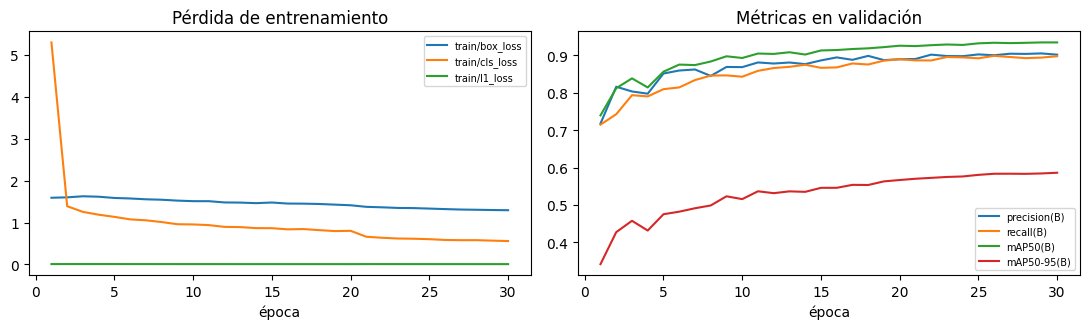

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
27,28,4580.16,1.30529,0.57934,0.00778,0.90317,0.89185,0.93277,0.58306,1.40503,0.58266,0.00856,0.000182,0.000182,0.000182
28,29,4787.49,1.29898,0.56794,0.00771,0.90448,0.89331,0.93380,0.58414,1.40325,0.58611,0.00856,0.000127,0.000127,0.000127
29,30,4997.66,1.29435,0.55808,0.00764,0.90106,0.89698,0.93381,0.58604,1.40287,0.57977,0.00856,0.000072,0.000072,0.000072


In [ ]:
# Curvas de entrenamiento (pérdida y métricas por época), generadas por Ultralytics
res = pd.read_csv(os.path.join(CARPETA_CORRIDA, "results.csv")); res.columns = [c.strip() for c in res.columns]
cols = [c for c in res.columns if c.startswith("metrics/")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for c in [c for c in res.columns if "loss" in c and c.startswith("train")]: ax[0].plot(res["epoch"], res[c], label=c)
ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("época"); ax[0].legend(fontsize=7)
for c in cols: ax[1].plot(res["epoch"], res[c], label=c.replace("metrics/", ""))
ax[1].set_title("Métricas en validación"); ax[1].set_xlabel("época"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_entrenamiento.png", dpi=150); plt.show()
res.tail(3)

## 3 · Evaluación en test con las métricas de Ultralytics (mAP)
`mAP50` mide qué tan bien coinciden las cajas con IoU ≥ 0,5 sobre **todas** las imágenes de test (no solo la muestra). Se usa el mejor modelo según validación; test no participó en el entrenamiento ni en esa elección.

In [ ]:
modelo = YOLO(MEJOR)
m = modelo.val(data=DATA_YAML, split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True, verbose=False)
nombres = [modelo.names[i] for i in m.box.ap_class_index]
TABLA_MAP = pd.DataFrame({"clase": nombres, "precisión": m.box.p, "recall": m.box.r, "mAP50": m.box.ap50, "mAP50-95": m.box.ap}).round(3)
TOTAL_MAP = {"mAP50": round(float(m.box.map50), 3), "mAP50-95": round(float(m.box.map), 3)}
print("Test completo -> mAP50:", TOTAL_MAP["mAP50"], "· mAP50-95:", TOTAL_MAP["mAP50-95"])
TABLA_MAP

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 95.5±164.4 MB/s, size: 56.8 KB)
val: Scanning /content/dataset/test/labels... 2001 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2001/2001 736.9it/s 2.7s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 126/126 6.2it/s 20.4s
                   all       2001       5518      0.921      0.899      0.947      0.602
Speed: 1.0ms preprocess, 4.5ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val
Test completo -> mAP50: 0.947 · mAP50-95: 0.602


,clase,precisión,recall,mAP50,mAP50-95
0,Hardhat,0.920,0.901,0.948,0.554
1,NO-Hardhat,0.922,0.896,0.946,0.651


## 4 · Comparación justa: modelo propio vs. modelo de Roboflow
Ambos se miden sobre **las mismas imágenes de la muestra de test**, con las mismas reglas (IoU ≥ 0,5, un acierto por caja real). El umbral del modelo propio se elige en *valid* (máx. F1 de "sin casco") y se evalúa **una sola vez** en test, igual que en la bitácora.

In [ ]:
def prf(tp, fp, fn):
    p = tp/(tp+fp) if tp+fp else 0.0; r = tp/(tp+fn) if tp+fn else 0.0
    return p, r, (2*p*r/(p+r) if p+r else 0.0)

def evaluar(muestra, preds, thr):
    tot = {c: Counter() for c in CATS}; gts = []; errores = []; filas = []
    for m in muestra:
        P = [p for p in preds[m["id"]] if p["conf"] >= thr]
        for c in CATS:
            g = [b for b in m["gt"] if b["cat"] == c]
            p = sorted([b for b in P if b["cat"] == c], key=lambda b: -b["conf"]); usado = set()
            for pb in p:
                mejor, bi = 0.0, None
                for i, gb in enumerate(g):
                    if i in usado: continue
                    v = iou(pb["box"], gb["box"])
                    if v > mejor: mejor, bi = v, i
                if bi is not None and mejor >= IOU_MIN:
                    usado.add(bi); tot[c]["tp"] += 1
                else:
                    tot[c]["fp"] += 1; errores.append({"img": m["id"], "tipo": "FP", "cat": c, "conf": pb["conf"], "box": pb["box"]})
            for i, gb in enumerate(g):
                ok = i in usado
                if not ok:
                    tot[c]["fn"] += 1; errores.append({"img": m["id"], "tipo": "FN", "cat": c, "conf": None, "box": gb["box"]})
                gts.append({"cat": c, "ok": ok, "area": gb["area"]})
        filas.append((any(b["cat"] == "sin_casco" for b in m["gt"]), any(b["cat"] == "sin_casco" for b in P)))
    ia = Counter()
    for g, p in filas: ia[("TP" if p else "FN") if g else ("FP" if p else "TN")] += 1
    return {"tot": tot, "gts": gts, "errores": errores, "img": ia}

In [ ]:
def predecir_local(modelo, muestra):
    out = {}; t0 = time.time()
    for m_ in muestra:
        r = modelo.predict(m_["path"], conf=CONF_MIN, imgsz=IMGSZ, verbose=False, device=DEVICE)[0]
        out[m_["id"]] = [{"cat": categoria(r.names[int(k)]), "clase": r.names[int(k)], "conf": float(c), "box": tuple(b)}
                         for b, c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist())]
    return out, (time.time() - t0) / max(1, len(muestra))

modelo.predict(MUESTRA_AJ[0]["path"], verbose=False, device=DEVICE)          # calentamiento (no cuenta en el tiempo)
PRED_L_AJ, _ = predecir_local(modelo, MUESTRA_AJ)
PRED_L_FIN, SEG_POR_IMG = predecir_local(modelo, MUESTRA_FIN)

UMBRALES = [round(x, 2) for x in np.arange(0.10, 0.951, 0.05)]
def f1_sin_casco(thr):
    t = evaluar(MUESTRA_AJ, PRED_L_AJ, thr)["tot"]["sin_casco"]; return prf(t["tp"], t["fp"], t["fn"])[2]
F1S = {t: f1_sin_casco(t) for t in UMBRALES}
UMBRAL_LOCAL = max(F1S, key=F1S.get)
print(f"Umbral del modelo propio elegido EN VALID: {UMBRAL_LOCAL} (F1 'sin casco' = {F1S[UMBRAL_LOCAL]:.3f})")

def fila(nombre, muestra, preds, thr, seg=None):
    e = evaluar(muestra, preds, thr); r = {"modelo": nombre, "umbral": thr, "imágenes": len(muestra)}
    for c in CATS:
        t = e["tot"][c]; p, rc, f1 = prf(t["tp"], t["fp"], t["fn"])
        r.update({f"P {NOMBRE[c]}": round(p, 3), f"R {NOMBRE[c]}": round(rc, 3), f"F1 {NOMBRE[c]}": round(f1, 3)})
    ia = e["img"]; r["Alerta: recall"] = round(ia["TP"]/(ia["TP"]+ia["FN"]), 3) if ia["TP"]+ia["FN"] else 0
    r["Alerta: precisión"] = round(ia["TP"]/(ia["TP"]+ia["FP"]), 3) if ia["TP"]+ia["FP"] else 0
    r["FN sin casco"] = ia["FN"]; r["FP sin casco"] = ia["FP"]; r["seg/imagen"] = round(seg, 3) if seg else None
    return r

FILAS = [fila("YOLO26 propio (local)", MUESTRA_FIN, PRED_L_FIN, UMBRAL_LOCAL, SEG_POR_IMG)]
if os.path.exists(PRED_ROBOFLOW_TEST):
    _c = json.load(open(PRED_ROBOFLOW_TEST)); PRED_RF = _c["preds"]
    comunes = [m_ for m_ in MUESTRA_FIN if m_["id"] in PRED_RF]
    if len(comunes) < len(MUESTRA_FIN):
        print(f"OJO: el archivo de Roboflow cubre {len(comunes)} de {len(MUESTRA_FIN)} imágenes; se compara solo sobre esas.")
        FILAS[0] = fila("YOLO26 propio (local)", comunes, PRED_L_FIN, UMBRAL_LOCAL, SEG_POR_IMG)
    FILAS.append(fila(f"Roboflow ({_c.get('model_id')})", comunes, PRED_RF, UMBRAL_ROBOFLOW))
else:
    print("No encontré", PRED_ROBOFLOW_TEST, "-> copia ahí el pred_test.json de la bitácora para comparar. Se muestra solo el modelo propio.")
COMPARACION = pd.DataFrame(FILAS)
COMPARACION.to_csv(os.path.join(SALIDA, "comparacion_modelos.csv"), index=False)
COMPARACION.T

Umbral del modelo propio elegido EN VALID: 0.4 (F1 'sin casco' = 0.769)
No encontré /content/drive/MyDrive/pred_test.json -> copia ahí el pred_test.json de la bitácora para comparar. Se muestra solo el modelo propio.


,0
modelo,YOLO26 propio (local)
umbral,0.4
imágenes,200
P Casco,0.918
R Casco,0.886
F1 Casco,0.901
P Sin casco,0.936
R Sin casco,0.914
F1 Sin casco,0.925
Alerta: recall,0.975


In [ ]:
# Copia final del modelo con un nombre claro, para usarlo en la app Gradio (sin API key)
MODELO_FINAL = os.path.join(SALIDA, "modelo_casco_yolo26.pt"); shutil.copy(MEJOR, MODELO_FINAL)
print("Modelo para la app:", MODELO_FINAL, f"({os.path.getsize(MODELO_FINAL)/1e6:.1f} MB)")
print("En Demo_Gradio_Casco.ipynb pon:  MODELO_LOCAL = '" + MODELO_FINAL + "'  (ya no pide API key)")

Modelo para la app: /content/drive/MyDrive/entrenamiento_casco/modelo_casco_yolo26.pt (5.5 MB)
En Demo_Gradio_Casco.ipynb pon:  MODELO_LOCAL = '/content/drive/MyDrive/entrenamiento_casco/modelo_casco_yolo26.pt'  (ya no pide API key)


## 5 · Conclusión (la escriben ustedes)
Con la tabla de comparación, respondan **con sus palabras** (esto va al informe y a la defensa):
- ¿Qué modelo conviene y por qué? Consideren el recall de "sin casco" (omitir a alguien es lo más grave), las falsas alarmas, la velocidad por imagen, el costo (créditos, API key) y la dependencia de internet.
- ¿Las diferencias son grandes o cabrían en el margen de error de una muestra de pocas imágenes?
- ¿Qué limitaciones comparten ambos? (imágenes estiradas a 640×640, dataset de terceros, poca diversidad de obras).
- Si el modelo propio es mejor o similar, ¿qué cambiarían en el prototipo?

**Honestidad con los resultados:** el modelo propio se entrenó con `train` y se evaluó en `test`; el de Roboflow es de terceros y no se sabe con qué imágenes se entrenó, así que su resultado en test puede estar inflado. Anótenlo.

**Uso de IA:** esta estructura y el código fueron apoyados por Claude; declaren en el README qué verificaron y modificaron.

In [ ]:
CONCLUSION = "COMPLETAR: conclusión propia basada en la tabla de comparación (mínimo 4-5 líneas)."
if "COMPLETAR" in CONCLUSION: print("PENDIENTE: escriban la conclusión (variable CONCLUSION) antes de entregar.")
print("Resumen para pegar en la bitácora / README")
print("Modelo propio:", MODELO_BASE, "| épocas:", EPOCAS, "| imgsz:", IMGSZ, "| batch:", BATCH, "| semilla:", SEED)
print("Test completo:", TOTAL_MAP)
print(COMPARACION.to_string(index=False))